# Spectral Clustering

K-Means (`27_kmeans`) assumes round clusters around a centre, so it cuts two interleaved moons or two concentric rings straight through. Spectral clustering groups points by **connectivity** instead: points that are linked by a chain of near neighbours belong together, whatever the shape.

## How it works

1. **Affinity graph.** Build a matrix `W` of how strongly each pair of points is connected:
   - `nearest_neighbors`: link each point to its `n_neighbors` closest (symmetrized) — the usual choice for curved shapes
   - `rbf`: `exp(−γ‖x − x'‖²)` for every pair
2. **Normalize.** With `D` the diagonal of row sums, take `M = D^(−1/2) · W · D^(−1/2)`. Its top-`k` eigenvectors are the bottom-`k` eigenvectors of the graph Laplacian `L = I − M`. A graph with `k` well-separated blobs has exactly `k` eigenvalues near 0 whose eigenvectors are (roughly) indicators of the blobs.
3. **Embed.** Each point becomes one row of that eigenvector matrix. In this space the tangled shapes are pulled apart into compact groups.
4. **Cluster the embedding** with ordinary K-Means (a small one is built in, so the folder stays self-contained).

It is a relaxed, tractable version of the graph-cut problem: cut the graph into `k` pieces while severing as little connection as possible.

Cost: dense `O(n²)` memory and an `O(n³)` eigendecomposition — fine for a few hundred to a few thousand points. You choose `k`; the demo and test show K-Means failing on the same data.

## Usage

```python
# (the class is defined in the Implementation section below)

labels = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=10).fit_predict(X)
labels = SpectralClustering(n_clusters=2, affinity="rbf", gamma=20.0).fit_predict(X)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _kmeans(X, k, rng, n_iters=100):
    """Tiny k-means++ / Lloyd, used on the spectral embedding."""
    centers = [X[rng.integers(len(X))]]
    for _ in range(1, k):
        d2 = np.min([((X - c) ** 2).sum(axis=1) for c in centers], axis=0)
        centers.append(X[rng.choice(len(X), p=d2 / d2.sum())] if d2.sum() > 0 else X[rng.integers(len(X))])
    centers = np.array(centers)
    for _ in range(n_iters):
        labels = ((X[:, None] - centers[None]) ** 2).sum(-1).argmin(axis=1)
        new = np.array([X[labels == c].mean(axis=0) if (labels == c).any() else centers[c] for c in range(k)])
        if np.allclose(new, centers):
            break
        centers = new
    return labels


class SpectralClustering:
    """Cluster by CONNECTIVITY instead of by distance to a centre, using a graph.

    1. Build an affinity matrix W: how strongly each pair of points is connected
       ("rbf": exp(-gamma * dist^2) for all pairs, or "nearest_neighbors": linked to their k nearest).
    2. Form the normalized matrix  M = D^-1/2 W D^-1/2  (D = diagonal of row sums). Its top-k
       eigenvectors are the bottom-k eigenvectors of the graph Laplacian  L = I - M.
    3. Each point becomes a row of that eigenvector matrix (its "spectral embedding"). In this new
       space, points in the same connected blob sit together -- even if the blob was a curve.
    4. Row-normalize and run plain K-Means in the embedding.

    This is how it separates shapes like two interleaved moons that K-Means (which assumes round
    clusters) cannot.

    ponytail: dense O(n^2) affinity and a full eigendecomposition O(n^3); use sparse graphs and
    Lanczos for large n."""

    def __init__(self, n_clusters=2, affinity="nearest_neighbors", gamma=1.0, n_neighbors=10,
                 random_state=0):
        self.n_clusters = n_clusters
        self.affinity = affinity
        self.gamma = gamma
        self.n_neighbors = n_neighbors
        self.random_state = random_state

    def _affinity_matrix(self, X):
        n = len(X)
        d2 = ((X[:, None] - X[None]) ** 2).sum(axis=2)
        if self.affinity == "rbf":
            W = np.exp(-self.gamma * d2)
        elif self.affinity == "nearest_neighbors":
            neighbors = np.argsort(d2, axis=1)[:, 1:self.n_neighbors + 1]  # skip the point itself
            A = np.zeros((n, n))
            A[np.repeat(np.arange(n), self.n_neighbors), neighbors.ravel()] = 1.0
            W = 0.5 * (A + A.T)  # symmetric: linked if either is among the other's neighbours
        else:
            raise ValueError(f"unknown affinity: {self.affinity}")
        np.fill_diagonal(W, 0.0)
        return W

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        W = self._affinity_matrix(X)
        d_inv_sqrt = 1.0 / np.sqrt(W.sum(axis=1))
        M = d_inv_sqrt[:, None] * W * d_inv_sqrt[None, :]

        eigenvalues, eigenvectors = np.linalg.eigh(M)  # ascending order
        embedding = eigenvectors[:, -self.n_clusters:]  # top-k = smallest Laplacian eigenvalues
        embedding = embedding / np.linalg.norm(embedding, axis=1, keepdims=True)

        self.affinity_matrix_ = W
        self.embedding_ = embedding
        self.labels_ = _kmeans(embedding, self.n_clusters, np.random.default_rng(self.random_state))
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_

## See it work

### 1. Connectivity beats distance-to-a-centre

Two interleaved moons and two concentric rings: K-Means (distance to a centre) cuts both straight through. Spectral clustering follows the **connectivity** of the points and recovers the true shapes.

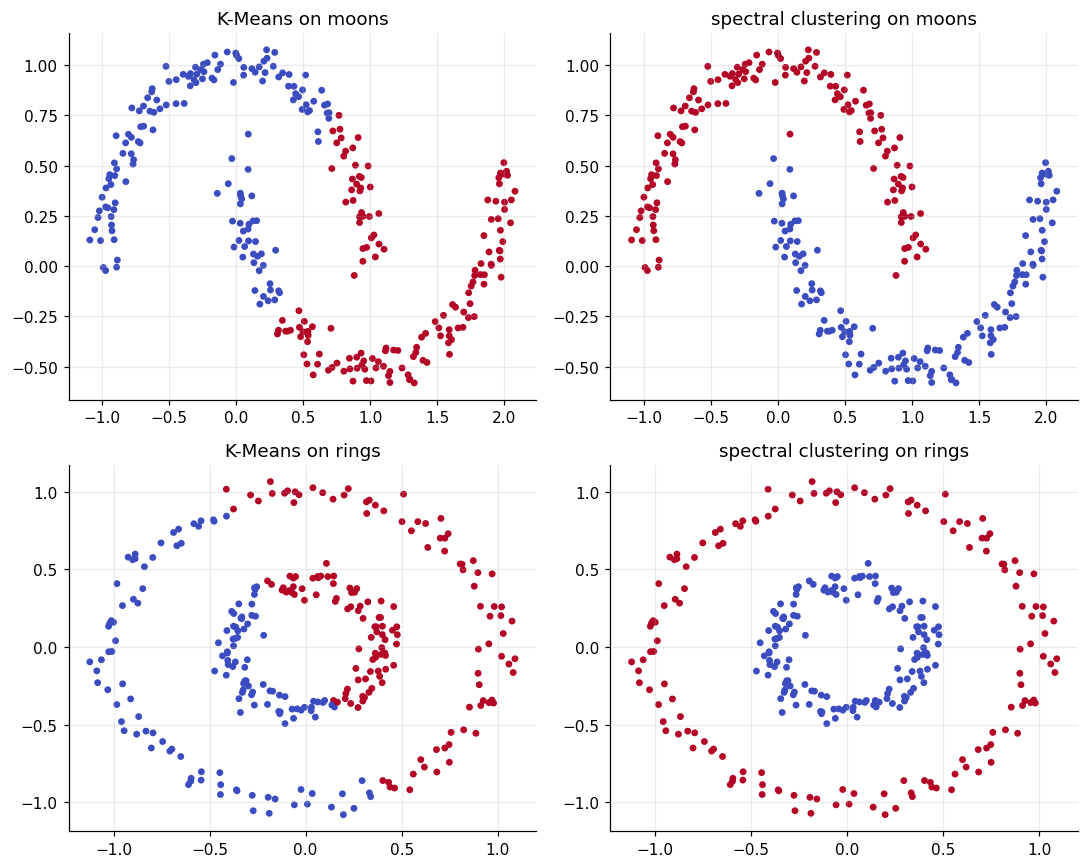

In [3]:
from sklearn.datasets import make_moons, make_circles
from sklearn.cluster import KMeans as SkKMeans

Xm, ym = make_moons(n_samples=300, noise=0.06, random_state=1)
Xc, yc = make_circles(n_samples=300, factor=0.4, noise=0.05, random_state=1)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (X, params, name) in enumerate([(Xm, dict(affinity="nearest_neighbors", n_neighbors=10), "moons"), (Xc, dict(affinity="rbf", gamma=20.0), "rings")]):
    axes[row, 0].scatter(*X.T, c=SkKMeans(2, n_init=10, random_state=0).fit_predict(X), cmap="coolwarm", s=12); axes[row, 0].set_title(f"K-Means on {name}")
    axes[row, 1].scatter(*X.T, c=SpectralClustering(n_clusters=2, **params).fit_predict(X), cmap="coolwarm", s=12); axes[row, 1].set_title(f"spectral clustering on {name}")
plt.tight_layout(); plt.show()

### 2. How: the affinity graph and the spectral embedding

Build a graph linking each point to its nearest neighbours. Sorting the points by cluster, the **affinity matrix** is block-diagonal: the points of a moon are connected mostly to each other. The eigenvectors of the (normalised) graph then map each point to a new space where the two moons are **compact, separated groups**, so plain K-Means can finish the job there.

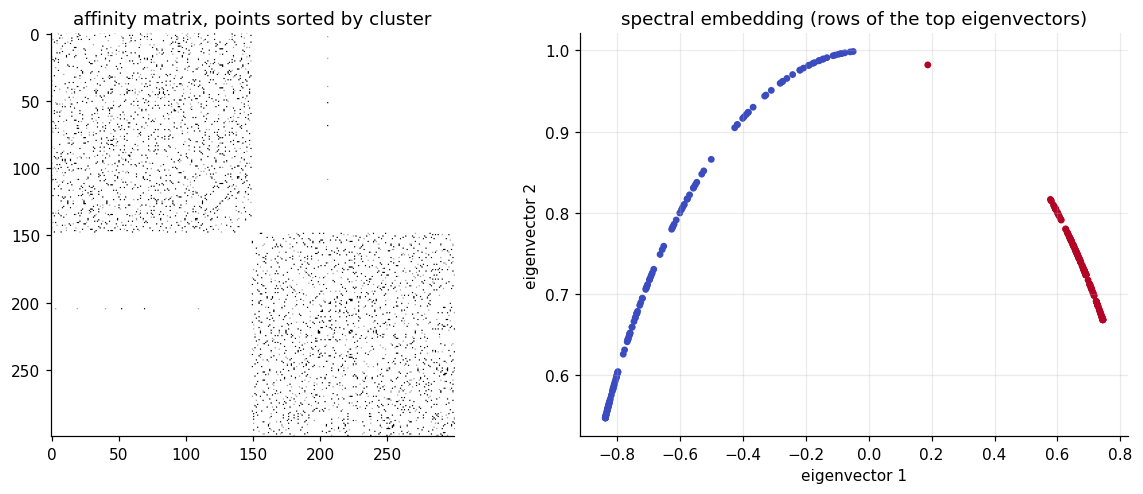

In [4]:
sc = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=10).fit(Xm)
order = np.argsort(sc.labels_)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.6))
a.imshow(sc.affinity_matrix_[np.ix_(order, order)], cmap="Greys"); a.set_title("affinity matrix, points sorted by cluster"); a.grid(False)
b.scatter(sc.embedding_[:, 0], sc.embedding_[:, 1], c=sc.labels_, cmap="coolwarm", s=12); b.set(title="spectral embedding (rows of the top eigenvectors)", xlabel="eigenvector 1", ylabel="eigenvector 2")
plt.tight_layout(); plt.show()

### 3. The graph is the model: `n_neighbors`

Too few neighbours and the graph falls apart into many disconnected pieces; too many and the two moons get linked, destroying the structure. Agreement with the true labels (adjusted Rand index):

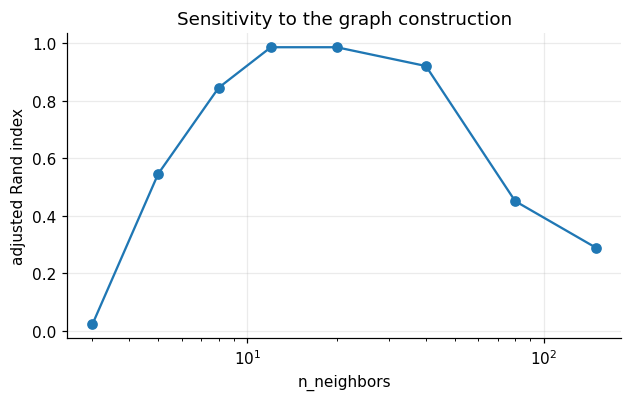

In [5]:
from sklearn.metrics import adjusted_rand_score
ks = [3, 5, 8, 12, 20, 40, 80, 150]
ari = [adjusted_rand_score(ym, SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=k).fit_predict(Xm)) for k in ks]
plt.figure(figsize=(6.5, 3.6)); plt.plot(ks, ari, "o-"); plt.xscale("log"); plt.xlabel("n_neighbors"); plt.ylabel("adjusted Rand index"); plt.title("Sensitivity to the graph construction"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.cluster import KMeans, SpectralClustering as SklearnSpectral
from sklearn.datasets import make_circles, make_moons
from sklearn.metrics import adjusted_rand_score

cases = {
    "two moons": (make_moons(n_samples=300, noise=0.06, random_state=1), dict(affinity="nearest_neighbors", n_neighbors=10)),
    "concentric circles": (make_circles(n_samples=300, factor=0.4, noise=0.05, random_state=1), dict(affinity="rbf", gamma=20.0)),
}

for name, ((X, truth), params) in cases.items():
    ours = SpectralClustering(n_clusters=2, **params).fit_predict(X)
    theirs = SklearnSpectral(n_clusters=2, random_state=0, **params).fit_predict(X)
    kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
    ari = lambda labels: adjusted_rand_score(truth, labels)
    print("%-19s agreement with the true shapes (ARI): ours=%.3f  sklearn=%.3f  kmeans=%.3f"
          % (name, ari(ours), ari(theirs), ari(kmeans)))
    assert ari(ours) > 0.95 and ari(theirs) > 0.95
    assert ari(kmeans) < 0.6

two moons           agreement with the true shapes (ARI): ours=0.987  sklearn=0.987  kmeans=0.241


concentric circles  agreement with the true shapes (ARI): ours=1.000  sklearn=1.000  kmeans=-0.003


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _moons(seed=0, n=200):
    from sklearn.datasets import make_moons

    return make_moons(n_samples=n, noise=0.05, random_state=seed)


def test_separates_interleaved_moons_where_kmeans_fails():
    from sklearn.cluster import KMeans
    from sklearn.metrics import adjusted_rand_score

    X, truth = _moons()
    spectral = SpectralClustering(n_clusters=2).fit_predict(X)
    kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
    assert adjusted_rand_score(truth, spectral) > 0.95
    assert adjusted_rand_score(truth, kmeans) < 0.6      # round-cluster assumption breaks on moons


def test_separates_concentric_circles_with_rbf_affinity():
    from sklearn.datasets import make_circles
    from sklearn.metrics import adjusted_rand_score

    X, truth = make_circles(n_samples=200, factor=0.4, noise=0.04, random_state=0)
    labels = SpectralClustering(n_clusters=2, affinity="rbf", gamma=20.0).fit_predict(X)
    assert adjusted_rand_score(truth, labels) > 0.95


def test_affinity_is_symmetric_and_embedding_rows_are_unit_length():
    X, _ = _moons(n=80)
    model = SpectralClustering(n_clusters=3).fit(X)
    W = model.affinity_matrix_
    assert np.allclose(W, W.T) and (np.diag(W) == 0).all()
    assert np.allclose(np.linalg.norm(model.embedding_, axis=1), 1.0)
    assert len(set(model.labels_)) == 3

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_separates_interleaved_moons_where_kmeans_fails
PASS test_separates_concentric_circles_with_rbf_affinity


PASS test_affinity_is_symmetric_and_embedding_rows_are_unit_length

all 3 tests passed


## Takeaways

- **Use it** for non-convex clusters when you know `k` and the data is small or medium (dense `n×n` affinity plus an eigendecomposition: `O(n²)` memory, `O(n³)` time).
- **Steps:** affinity graph → normalised matrix `D^−½ W D^−½` → top-`k` eigenvectors → row-normalise → K-Means in the embedding. It is a relaxation of the normalised graph-cut problem.
- **Pitfalls:** you must choose `k`, and the affinity (neighbour count or `gamma`) matters a lot; poor scaling.
- **Interview line:** *"Cluster the rows of the first `k` eigenvectors of the graph Laplacian: it approximates the minimum normalised cut, so it respects connectivity instead of distance to a centre."*